# 02 - Análisis exploratorio (EDA) de las transacciones

Entrada: `data/processed/transacciones.csv` (salida de `src/data/mapeo.py`: compras de H&M ya mapeadas a items de Siman, con `split` temporal) y `data/processed/catalogo.csv`. Las gráficas se guardan en `reports/figuras/` como `eda_tx_<tema>.png`.
Cada fila es una compra de un item por un cliente; "compras" siempre significa filas.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

os.makedirs("../reports/figuras", exist_ok=True)
tx = pd.read_csv("../data/processed/transacciones.csv", dtype={"customer_id": str, "item_id": str},
                 parse_dates=["t_dat"])
cat = pd.read_csv("../data/processed/catalogo.csv", dtype={"item_id": str},
                  usecols=["item_id", "seccion", "tipo_prenda"])
SPLITS = ["train", "val", "test"]
INICIO_VAL = pd.Timestamp("2020-09-09")

# Estilo: superficie clara, tinta en grises, un solo color de serie (azul)
SUPERFICIE, TINTA, TINTA2, MUDO = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, EJE, AZUL, GRIS = "#e1e0d9", "#c3c2b7", "#2a78d6", "#a8a79f"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "text.color": TINTA,
    "xtick.color": MUDO, "ytick.color": MUDO, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlepad": 12,
    "font.size": 10, "figure.dpi": 100,
})
miles = lambda x, _: f"{x:,.0f}"  # separador de miles en los ejes

# Un color por split: train azul (el de la serie), val naranja, test verde
COLOR_SPLIT = {"train": AZUL, "val": "#e8923a", "test": "#2e9e6a"}

## 1. Resumen

In [2]:
def resumen(d):
    return {"filas": len(d), "clientes": d["customer_id"].nunique(), "items": d["item_id"].nunique(),
            "desde": d["t_dat"].min().date(), "hasta": d["t_dat"].max().date()}

res = pd.DataFrame({**{s: resumen(tx[tx["split"] == s]) for s in SPLITS}, "total": resumen(tx)}).T
res["días"] = [(r.hasta - r.desde).days + 1 for r in res.itertuples()]
for col in ["filas", "clientes", "items"]:
    res[col] = res[col].map("{:,}".format)
res

,filas,clientes,items,desde,hasta,días
train,"499,647","48,186","8,421",2020-03-24,2020-09-08,169
val,"16,664","4,773","2,967",2020-09-09,2020-09-15,7
test,"15,901","4,592","2,787",2020-09-16,2020-09-22,7
total,"532,212","49,891","8,614",2020-03-24,2020-09-22,183


**Hallazgo:** 532,212 compras de 49,891 clientes sobre 8,614 items distintos. Train concentra 499,647 compras (93.9 %) en 169 días; val y test son una semana cada uno, con 16,664 y 15,901 compras (4,773 y 4,592 clientes). Los clientes por split no suman el total porque el mismo cliente aparece en varios.

## 2. Compras por cliente (train)

Clientes en train: 48,186   compras: 499,647
Media 10.4   mediana 6   P90 24   P99 63   máximo 409
Clientes con 1 sola compra: 4,971 (10.3%)
Clientes con 64 o más compras: 459 (1.0%)


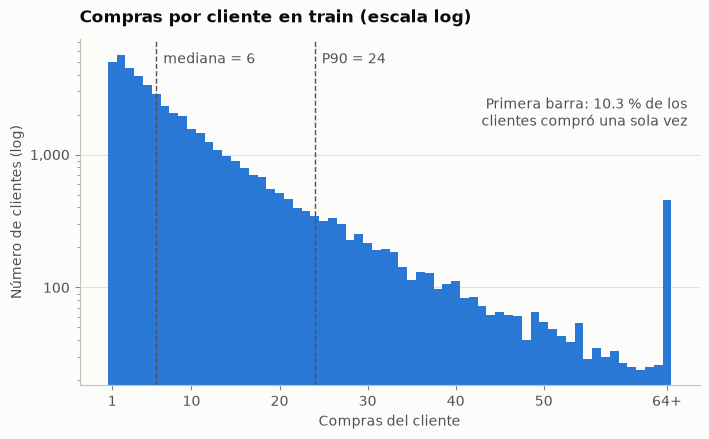

In [3]:
compras = tx[tx["split"] == "train"].groupby("customer_id").size()
mediana, p90, p99 = compras.median(), compras.quantile(0.90), compras.quantile(0.99)
print(f"Clientes en train: {len(compras):,}   compras: {compras.sum():,}")
print(f"Media {compras.mean():.1f}   mediana {mediana:.0f}   P90 {p90:.0f}   P99 {p99:.0f}   máximo {compras.max()}")
print(f"Clientes con 1 sola compra: {(compras == 1).sum():,} ({(compras == 1).mean():.1%})")

TOPE = 64  # los clientes con 64 o más compras se agrupan en la última barra
print(f"Clientes con {TOPE} o más compras: {(compras >= TOPE).sum():,} ({(compras >= TOPE).mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(compras.clip(upper=TOPE), bins=np.arange(0.5, TOPE + 1.5), color=AZUL)
ax.set_yscale("log")
for valor, nombre in [(mediana, "mediana"), (p90, "P90")]:
    ax.axvline(valor, color=TINTA2, ls="--", lw=1)
    ax.text(valor + 0.8, 0.93, f"{nombre} = {valor:.0f}", transform=ax.get_xaxis_transform(), color=TINTA2)
ax.text(0.98, 0.75, f"Primera barra: {(compras == 1).mean() * 100:.1f} % de los\nclientes compró una sola vez",
        transform=ax.transAxes, ha="right", color=TINTA2)
ax.set_title("Compras por cliente en train (escala log)")
ax.set_xlabel("Compras del cliente")
ax.set_ylabel("Número de clientes (log)")
ax.set_xticks([1, 10, 20, 30, 40, 50, TOPE])
ax.set_xticklabels([1, 10, 20, 30, 40, 50, f"{TOPE}+"])
ax.yaxis.set_major_formatter(miles)
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_tx_compras_cliente.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** los historiales son cortos: mediana de 6 compras por cliente, P90 de 24 y máximo de 409. 4,971 clientes (10.3 %) compraron una sola vez y solo 459 (1.0 %) llegan a 64 o más compras.

## 3. Popularidad de items (cola larga)

Prendas del catálogo: 11,786   con al menos 1 compra: 8,614
Prendas que nunca reciben una compra: 3,172 (26.9%)
Sin compras en train: 3,365
Top 10 items = 8.2% de las compras   top 100 = 23.9%
Items que juntan el 50 % de las compras: 461 (3.9% del catálogo)
Items que juntan el 80 % de las compras: 1,550 (13.2% del catálogo)
Item más comprado: 14,185 compras (2.7%)


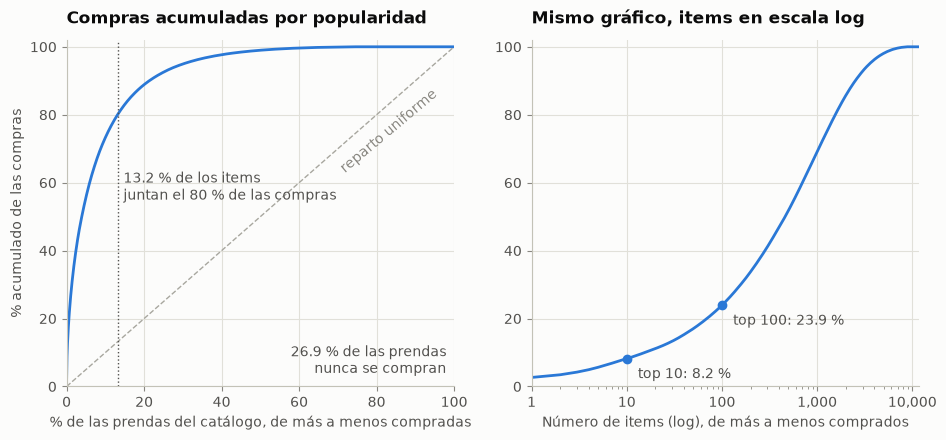

In [4]:
assert cat["item_id"].is_unique and tx["item_id"].isin(cat["item_id"]).all()

# Compras por item sobre todo el periodo; las prendas del catálogo sin compras quedan en 0
por_item = tx["item_id"].value_counts().reindex(cat["item_id"], fill_value=0).sort_values(ascending=False)
assert por_item.sum() == len(tx)
n_items = len(por_item)
acum = por_item.cumsum() / por_item.sum()
sin_compra = int((por_item == 0).sum())
items_50, items_80 = int((acum < 0.5).sum()) + 1, int((acum < 0.8).sum()) + 1
top10, top100 = acum.iloc[9], acum.iloc[99]

print(f"Prendas del catálogo: {n_items:,}   con al menos 1 compra: {n_items - sin_compra:,}")
print(f"Prendas que nunca reciben una compra: {sin_compra:,} ({sin_compra / n_items:.1%})")
print(f"Sin compras en train: {n_items - tx.loc[tx['split'] == 'train', 'item_id'].nunique():,}")
print(f"Top 10 items = {top10:.1%} de las compras   top 100 = {top100:.1%}")
print(f"Items que juntan el 50 % de las compras: {items_50:,} ({items_50 / n_items:.1%} del catálogo)")
print(f"Items que juntan el 80 % de las compras: {items_80:,} ({items_80 / n_items:.1%} del catálogo)")
print(f"Item más comprado: {por_item.iloc[0]:,} compras ({por_item.iloc[0] / len(tx):.1%})")

pos = np.arange(1, n_items + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.plot(pos / n_items * 100, acum.values * 100, color=AZUL, lw=2)
ax1.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1)
ax1.axvline(items_80 / n_items * 100, color=TINTA2, ls=":", lw=1)
ax1.text(items_80 / n_items * 100 + 1.5, 55, f"{items_80 / n_items * 100:.1f} % de los items\njuntan el 80 % de las compras",
         color=TINTA2)
ax1.text(98, 4, f"{sin_compra / n_items * 100:.1f} % de las prendas\nnunca se compran", ha="right", color=TINTA2)
ax1.text(70, 63, "reparto uniforme", color=MUDO, rotation=40)
ax1.set_title("Compras acumuladas por popularidad")
ax1.set_xlabel("% de las prendas del catálogo, de más a menos compradas")
ax1.set_ylabel("% acumulado de las compras")
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 102)
ax1.grid()

ax2.plot(pos, acum.values * 100, color=AZUL, lw=2)
ax2.set_xscale("log")
for k, v in [(10, top10), (100, top100)]:
    ax2.plot([k], [v * 100], "o", color=AZUL)
    ax2.annotate(f"top {k}: {v * 100:.1f} %", (k, v * 100), xytext=(8, -14), textcoords="offset points", color=TINTA2)
ax2.set_title("Mismo gráfico, items en escala log")
ax2.set_xlabel("Número de items (log), de más a menos comprados")
ax2.set_xlim(1, n_items)
ax2.set_ylim(0, 102)
ax2.xaxis.set_major_formatter(miles)
ax2.grid()
plt.savefig("../reports/figuras/eda_tx_popularidad.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** cola larga. El top 10 junta el 8.2 % de las compras y el top 100 el 23.9 %; 461 items (3.9 % del catálogo) bastan para el 50 % de las compras y 1,550 (13.2 %) para el 80 %. 3,172 de las 11,786 prendas (26.9 %) nunca reciben una compra, y son 3,365 si solo se cuenta train.

## 4. Compras por semana

Las semanas son bloques de 7 días alineados con el inicio de val (2020-09-09), así que val y test son exactamente una semana cada uno. Como train empieza un día antes de lo que cuadra, el primer bloque es de un solo día (24-mar).

Semanas completas en train: 24   media 20,732 compras/semana   mín 13,725   máx 36,545
Semanas más altas: 2020-06-17 (36,545), 2020-06-24 (33,779)
Últimas 3 semanas de train: 16,637, 18,418, 17,083
Semana de val: 16,664 compras (-19.6% vs. media de train)
Semana de test: 15,901 compras (-23.3% vs. media de train)
Bloque parcial: 2020-03-24 (1 día, 2,086 compras)
Semanas de julio en adelante (train): de 16,637 a 21,965


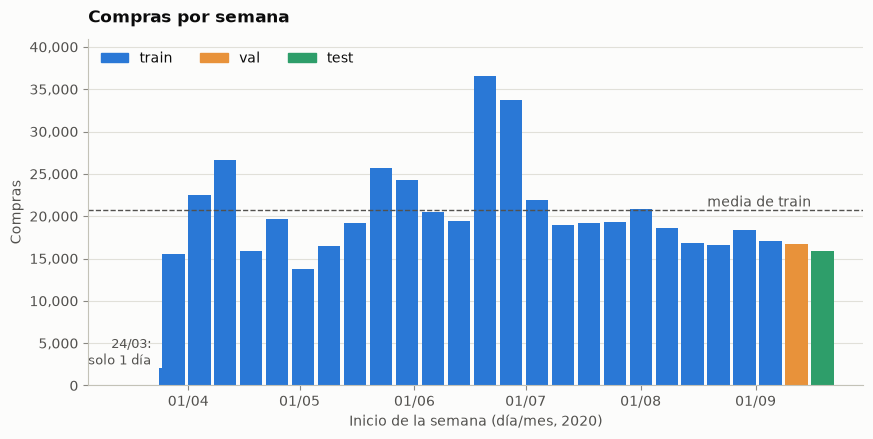

In [5]:
sem = (tx["t_dat"] - INICIO_VAL).dt.days // 7  # 0 = semana de val, -1 = última de train
por_sem = tx.groupby(sem).agg(compras=("item_id", "size"), dias=("t_dat", "nunique"),
                              split=("split", "nunique"), clientes=("customer_id", "nunique"))
assert (por_sem["split"] == 1).all(), "una semana mezcla splits"
por_sem["split"] = tx.groupby(sem)["split"].first()
por_sem["inicio"] = tx.groupby(sem)["t_dat"].min()  # primer día con datos de cada bloque
completas = por_sem[por_sem["dias"] == 7]
tr = completas[completas["split"] == "train"]

print(f"Semanas completas en train: {len(tr)}   media {tr['compras'].mean():,.0f} compras/semana"
      f"   mín {tr['compras'].min():,}   máx {tr['compras'].max():,}")
print("Semanas más altas:", ", ".join(
    f"{f.date()} ({n:,})" for f, n in tr.nlargest(2, "compras").set_index("inicio")["compras"].items()))
print("Últimas 3 semanas de train:", ", ".join(f"{n:,}" for n in tr["compras"].tail(3)))
for s in ["val", "test"]:
    n = por_sem.loc[por_sem["split"] == s, "compras"].iloc[0]
    print(f"Semana de {s}: {n:,} compras ({n / tr['compras'].mean() - 1:+.1%} vs. media de train)")
print(f"Bloque parcial: {por_sem['inicio'].iloc[0].date()} ({por_sem['dias'].iloc[0]} día, {por_sem['compras'].iloc[0]:,} compras)")
print(f"Semanas de julio en adelante (train): de {tr[tr['inicio'] >= '2020-07-01']['compras'].min():,} a {tr[tr['inicio'] >= '2020-07-01']['compras'].max():,}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ancho = np.where(por_sem["dias"] == 7, 6, 1)  # el bloque de un día se dibuja de un día
ax.bar(por_sem["inicio"], por_sem["compras"], width=ancho, align="edge",
       color=[COLOR_SPLIT[s] for s in por_sem["split"]])
ax.text(por_sem["inicio"].iloc[0] - pd.Timedelta(days=2), por_sem["compras"].iloc[0] + 400,
        "24/03:\nsolo 1 día", ha="right", color=TINTA2, fontsize=9)
ax.axhline(tr["compras"].mean(), color=TINTA2, ls="--", lw=1)
ax.text(por_sem["inicio"].iloc[-1], tr["compras"].mean() * 1.02, "media de train", ha="right", color=TINTA2)
ax.legend(handles=[Patch(color=COLOR_SPLIT[s], label=s) for s in SPLITS], frameon=False, loc="upper left", ncol=3)
ax.set_xlim(pd.Timestamp("2020-03-05"), pd.Timestamp("2020-09-30"))
ax.set_title("Compras por semana")
ax.set_xlabel("Inicio de la semana (día/mes, 2020)")
ax.set_ylabel("Compras")
ax.set_ylim(0, por_sem["compras"].max() * 1.12)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.yaxis.set_major_formatter(miles)
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_tx_semana.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** la media en train es de 20,732 compras por semana (24 semanas completas), con picos de 36,545 (semana que empieza el 17-jun) y 33,779 (24-jun); desde julio van de 16,637 a 21,965. Las semanas de val (16,664) y test (15,901) quedan 19.6 % y 23.3 % por debajo de esa media, en línea con las últimas semanas de train (16,637 a 18,418). El 24-mar es un bloque de un solo día (2,086 compras).

## 5. Compras vs. catálogo por sección

La sección es la del item de Siman que recibe la compra.

         prendas  compras  % catálogo  % compras  compras / catálogo
seccion                                                             
mujer       5493   493171        46.6       92.7                1.99
hombre      3132    30122        26.6        5.7                0.21
bebe        1130     2832         9.6        0.5                0.05
nina         988     3288         8.4        0.6                0.07
nino         912     2787         7.7        0.5                0.06
unisex       131       12         1.1        0.0                0.00


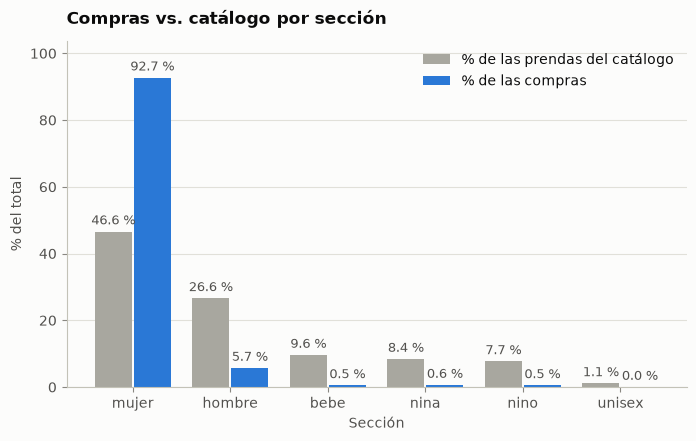

In [6]:
compras_sec = tx.merge(cat[["item_id", "seccion"]], on="item_id")["seccion"].value_counts()
sec = pd.DataFrame({"prendas": cat["seccion"].value_counts(), "compras": compras_sec}).fillna(0).astype(int)
sec = sec.sort_values("prendas", ascending=False)
sec["% catálogo"] = (sec["prendas"] / sec["prendas"].sum() * 100).round(1)
sec["% compras"] = (sec["compras"] / sec["compras"].sum() * 100).round(1)
sec["compras / catálogo"] = (sec["% compras"] / sec["% catálogo"]).round(2)
print(sec.to_string())

x = np.arange(len(sec))
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - 0.2, sec["% catálogo"], width=0.38, color=GRIS, label="% de las prendas del catálogo")
b2 = ax.bar(x + 0.2, sec["% compras"], width=0.38, color=AZUL, label="% de las compras")
for b in (b1, b2):
    ax.bar_label(b, labels=[f"{v:.1f} %" for v in (sec["% catálogo"] if b is b1 else sec["% compras"])],
                 padding=3, color=TINTA2, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(sec.index)
ax.legend(frameon=False, loc="upper right")
ax.set_title("Compras vs. catálogo por sección")
ax.set_xlabel("Sección")
ax.set_ylabel("% del total")
ax.set_ylim(0, sec["% compras"].max() * 1.12)
ax.grid(axis="y")
plt.savefig("../reports/figuras/eda_tx_seccion.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** sesgo fuerte hacia mujer: 92.7 % de las compras (493,171) con 46.6 % del catálogo (5,493 prendas), casi el doble de lo que le tocaría. Hombre recibe 5.7 % de las compras con 26.6 % de las prendas, y bebé, niña y niño juntos 1.7 % con 25.7 %. Unisex tiene 131 prendas y solo 12 compras.

## 6. Chequeos de fuga y arranque en frío

Los splits son temporales: train va hasta 2020-09-08, val es la semana siguiente y test la última. Primero se comprueba que no hay traslape; después, qué tan nuevo es lo que aparece en val y test respecto a train.

              min         max
split                        
train  2020-03-24  2020-09-08
val    2020-09-09  2020-09-15
test   2020-09-16  2020-09-22
Días sin datos entre splits: 0 (train-val), 0 (val-test)



                                             val    test
clientes                                   4,773   4,592
% clientes con historial en train           81.8    80.1
items comprados                            2,967   2,787
% items nunca vistos en train                3.7     4.1
% compras (filas) de items nunca vistos      1.0     1.5
pares (cliente, item)                     14,620  13,834
% pares ya comprados en train (recompra)     4.6     3.1
% recompra, solo clientes con historial      5.6     3.8



Filas de train que repiten un (cliente, item) ya visto en train: 17.4%   (el mismo día: 13.0%, otro día: 4.4%)


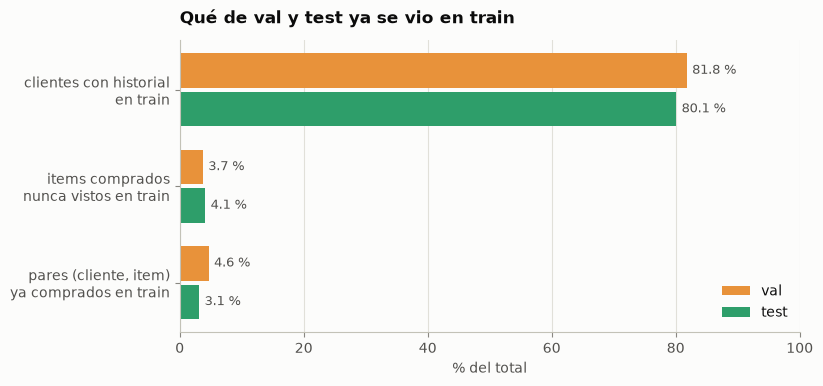

In [7]:
# Integridad básica y orden de las fechas
assert tx.notna().all().all() and set(tx["split"]) == set(SPLITS)
fechas = tx.groupby("split")["t_dat"].agg(["min", "max"]).loc[SPLITS]
print(fechas.assign(**{c: fechas[c].dt.date for c in fechas}).to_string())
assert fechas.loc["train", "max"] < fechas.loc["val", "min"], "train y val se traslapan"
assert fechas.loc["val", "max"] < fechas.loc["test", "min"], "val y test se traslapan"
print("Días sin datos entre splits:",
      (fechas.loc["val", "min"] - fechas.loc["train", "max"]).days - 1, "(train-val),",
      (fechas.loc["test", "min"] - fechas.loc["val", "max"]).days - 1, "(val-test)")

# Qué de val y test ya se vio en train
train = tx[tx["split"] == "train"]
clientes_train, items_train = set(train["customer_id"]), set(train["item_id"])
pares_train = train[["customer_id", "item_id"]].drop_duplicates()
filas = {}
for s in ["val", "test"]:
    d = tx[tx["split"] == s]
    clientes, items = d["customer_id"].drop_duplicates(), d["item_id"].drop_duplicates()
    pares = d[["customer_id", "item_id"]].drop_duplicates()
    pares = pares.merge(pares_train, how="left", indicator=True)
    pares["recompra"] = pares["_merge"] == "both"
    pares["historial"] = pares["customer_id"].isin(clientes_train)
    filas[s] = {
        "clientes": len(clientes),
        "% clientes con historial en train": clientes.isin(clientes_train).mean() * 100,
        "items comprados": len(items),
        "% items nunca vistos en train": (~items.isin(items_train)).mean() * 100,
        "% compras (filas) de items nunca vistos": (~d["item_id"].isin(items_train)).mean() * 100,
        "pares (cliente, item)": len(pares),
        "% pares ya comprados en train (recompra)": pares["recompra"].mean() * 100,
        "% recompra, solo clientes con historial": pares.loc[pares["historial"], "recompra"].mean() * 100,
    }
frio = pd.DataFrame(filas)
print()
print(frio.apply(lambda f: f.map(lambda v: f"{v:.1f}" if f.name.startswith("%") else f"{v:,.0f}"), axis=1).to_string())

# Repeticiones dentro de train (varios artículos de H&M pueden caer en el mismo item de Siman)
rep_par = train.duplicated(["customer_id", "item_id"])
rep_dia = train.duplicated(["customer_id", "item_id", "t_dat"])
print(f"\nFilas de train que repiten un (cliente, item) ya visto en train: {rep_par.mean():.1%}"
      f"   (el mismo día: {rep_dia.mean():.1%}, otro día: {(rep_par & ~rep_dia).mean():.1%})")

metricas = ["% clientes con historial en train", "% items nunca vistos en train",
            "% pares ya comprados en train (recompra)"]
y = np.arange(len(metricas))[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
for desplazo, s in [(0.2, "val"), (-0.2, "test")]:
    barras = ax.barh(y + desplazo, frio.loc[metricas, s], height=0.36, color=COLOR_SPLIT[s], label=s)
    ax.bar_label(barras, labels=[f"{v:.1f} %" for v in frio.loc[metricas, s]], padding=4, color=TINTA2, fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(["clientes con historial\nen train", "items comprados\nnunca vistos en train",
                    "pares (cliente, item)\nya comprados en train"])
ax.legend(frameon=False, loc="lower right")
ax.set_title("Qué de val y test ya se vio en train")
ax.set_xlabel("% del total")
ax.set_xlim(0, 100)
ax.grid(axis="x")
plt.savefig("../reports/figuras/eda_tx_arranque_frio.png", dpi=150, bbox_inches="tight")
plt.show()

**Hallazgo:** los splits no se traslapan y son consecutivos (0 días de hueco). El 81.8 % de los clientes de val y el 80.1 % de test tienen historial en train, o sea que cerca de 1 de cada 5 llega sin historial. Los items nuevos pesan poco: 3.7 % (val) y 4.1 % (test) de los items comprados nunca aparecen en train, y son 1.0 % y 1.5 % de las compras. La recompra es baja: 4.6 % de los pares (cliente, item) de val y 3.1 % de test ya se habían comprado en train (3.8 % entre los clientes de test con historial). Dentro de train, 17.4 % de las filas repiten un par ya visto, 13.0 % el mismo día (en su mayoría el mismo artículo de H&M comprado varias veces el mismo día, que viene en filas separadas).

## 7. Hallazgos para el modelado

- **Historiales cortos y matriz dispersa.** Mediana de 6 compras por cliente y 10.3 % con una sola; los modelos de embeddings de clientes tendrán poca señal para la mayoría, y conviene depurar los pares repetidos (13.0 % de las filas de train son el mismo cliente, item y día).
- **Cola larga de items.** El top 100 junta el 23.9 % de las compras y 26.9 % del catálogo nunca se compra (3,365 prendas sin compras en train): un modelo que solo aprende por ID no puede recomendar esas prendas, así que hacen falta atributos o contenido (texto, imagen) para llegar a ellas. La línea base de más comprados ya es una referencia fuerte.
- **Sesgo hacia mujer.** 92.7 % de las compras son de mujer y hombre y niños reciben 7.3 % entre todos; las métricas globales las manda mujer, así que conviene reportar también por sección.
- **Arranque en frío de clientes.** Entre 18 % y 20 % de los clientes de val y test no tienen historial en train; necesitan un recomendador de respaldo (más comprados recientes, quizá por sección).
- **Pocos items nuevos y poca recompra.** Solo 3.7 %-4.1 % de los items de val y test no aparecen en train, y solo 3.1 %-4.6 % de los pares ya se habían comprado: se pueden excluir de las recomendaciones los items que el cliente ya compró, y el arranque en frío de items es un problema menor.
- **Demanda no estacionaria y splits sin fuga.** Las semanas de val y test están entre 20 % y 23 % por debajo de la media de train y hubo un pico a finales de junio; los splits son temporales sin traslape, así que los modelos deben entrenarse y construir sus rasgos solo con train (la línea base usa la última semana previa al periodo evaluado).